In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator

from typing import Union, List

import frb_functions

In [8]:
frb_functions.mask_array?

Signature: frb_functions.mask_array(array, bad_chan_idx)
Docstring:
Masks entire rows in a 2D NumPy array.

Converts the input array into a masked array and masks the rows specified 
in `bad_chan_idx`, ignoring them in computations.

Parameters:
-----------
array : numpy.ndarray
    A 2D NumPy array.
bad_chan_idx : list of int
    Indices of rows to be masked.

Returns:
--------
numpy.ma.MaskedArray
    The input array with specified rows masked.

Example:
--------
>>> arr = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
>>> mask_array(arr, [1])
masked_array(
  data=[[1, 2, 3],
        [--, --, --],
        [7, 8, 9]],
  mask=[[False, False, False],
        [ True,  True,  True],
        [False, False, False]]
)
File:      ~/git/mimir/scripts/frb_functions.py
Type:      function

In [2]:
def gaus(x,a,x0,sigma,d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))+d

In [51]:
def waterfaller_maker(burst, DM, offset_sec, id, window=5, downsamp_t=1, downsamp_f=1, \
                      plot_spectrum=False, save_bool=False, wind_spectrum=None, dededisp=None):
    
    #Define the figure
    fig5 = plt.figure(figsize=(10,10))

    rows = 2
    cols = 1    
    if plot_spectrum: cols += 1
    widths = [1]
    heights = [1, 1.5]
    spec5 = fig5.add_gridspec(ncols=cols, nrows=rows, \
                          height_ratios=[0.6, 1.4], \
                          width_ratios=[5,]+[1,]*(cols-1), \
                          wspace=0.0, hspace=0.0)
    # spec5 = fig5.add_gridspec(ncols=cols, nrows=rows, \
    #                           height_ratios=[1,]*(rows-1)+[2,], width_ratios=[5,]+[1,]*(cols-1),
    #                           #width_ratios=widths, height_ratios=heights,\
    #                           wspace=0.0, hspace=0.0)

    # #Gridspec in Gridspec
    # rows = 2
    # cols = 1
    # if plot_spectrum: cols += 1
    # plot_grid = gridspec.GridSpecFromSubplotSpec(rows, cols, plot_grid_idx, wspace=0., hspace=0.,
    #                                              height_ratios=[1,]*(rows-1)+[2,], width_ratios=[5,]+[1,]*(cols-1))
    
    # ax1 = plt.Subplot(fig, plot_grid[rows-1,0])
    # ax2 = plt.Subplot(fig, plot_grid[rows-2,0], sharex=ax1)
    #ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax2)
    

    ###################################
    #Loading in the burst
    burst = your.Your(burst)

    #Getting the info of the headerfile
    header_dict = frb_functions.your_header_to_dict(burst)
    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    freqs = header_dict["freqs"] # in Mhz
    
    #Extracting the extent
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    #Aligning the burst in the middle
    offset = offset_sec
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    #Loading in the data, pol1 (StokesI)
    print("loading in the data")
    d = frb_functions.get_data(burst,nstart=0, nsamp=nbins, npoln=1)

    #De-dispersing in case you want to change the DM from the original
    if dededisp != None:
        print(f"de-de-dispersing to DM zero using {dededisp} pc/cc")
        d = frb_functions.dedisperse(d,dededisp,freqs,tsamp)

    #Dedispersing the data
    dm_dedisp = DM
    print(f"de-dispersing to {dm_dedisp} pc/cc")
    stokes_i = frb_functions.dedisperse(d,dm_dedisp,freqs,tsamp)

    #Correcting the bandpass
    print(f"Correcting for the bandpass")
    stokes_i_norm = frb_functions.correct_bandpass(stokes_i, scale=3, sides="right")

    #In case of downsampling
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i_norm = frb_functions.downsample(stokes_i_norm, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i_norm = frb_functions.correct_bandpass(stokes_i_norm, scale=3, sides="right")
        downsamp_flag = True

        #Very specific for p47028_o8
        bad_chans_1 = np.arange(0,512/downsamp_f,dtype=int)
        bad_chans_2 = np.arange(4064/downsamp_f,4095/downsamp_f,dtype=int)
        bad_chans = np.concatenate((bad_chans_1, bad_chans_2), axis=None)
        
    else:
        downsamp_flag = False

    #Masking Subband edges
    print(f"Masking subband edges")
    nchans = header_dict["nchans"]
    bw = header_dict["bw"] * -1
    print(f"channel numbers: {nchans}")
    nchans_n = nchans/downsamp_f
    subband_edges_arr = frb_functions.get_subband_edges(bandwidth=bw, n_chan=int(nchans/downsamp_f))
    stokes_i_norm = frb_functions.mask_array(stokes_i_norm, subband_edges_arr)     

    print(f"Masking bad channels")
    stokes_i_norm = frb_functions.mask_array(stokes_i_norm, bad_chans)
    stokes_i_norm = frb_functions.correct_bandpass(stokes_i_norm, scale=3, sides="right")
    
    new_quantiles = np.nanpercentile(stokes_i_norm.compressed(), (1.0, 99.99))

    #Without masking use this expression
    #new_quantiles = np.percentile(stokes_i, (1.0, 99.9))
    
    #Setting up the dynamic spectra [ax2]
    ax2 = fig5.add_subplot(spec5[1, 0]) 
    ax2.imshow(stokes_i_norm, aspect='auto', interpolation='None',\
          extent=extent_b, vmin=new_quantiles[0], vmax=new_quantiles[1])
    window_ms = window
    ax2.set_xlim(-window_ms,window_ms)
    ax2.set_ylabel('Frequency (MHz)',size=25)
    ax2.set_xlabel('Time (ms)',size=25)
    ax2.yaxis.set_major_locator(ticker.LinearLocator(5))
    ax2.xaxis.set_minor_locator(ticker.MultipleLocator(10))

    #Create x grid to plot the step function of the time series
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i_norm.shape[1])
    prof = np.mean(stokes_i_norm,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof,sides="right", scale=3)
    
    ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax2)
    ax1.set_ylabel('S/N',size=25)
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-post', color='black')
    
    #Ticks on the SN-
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0,int(maxSN/2),int(maxSN)])
    ax1.set_yticks(yticks_sn)
    
    if plot_spectrum: 
        ax3 = fig5.add_subplot(spec5[1, 1], sharey=ax2) #Drawing

        #We know the time of the burst, since it's stored in offset (in sec)

        burst_bin = offset / tsamp #The bin where the offset is defined
        spectrum_window_ms = wind_spectrum #How large the window should be by eye in ms
        spectrum_window_bins = int(spectrum_window_ms / (tsamp*1e3))

        spectrum_beg = burst_bin-(spectrum_window_bins/2)
        spectrum_end = burst_bin+(spectrum_window_bins/2)
        spectrum_arr_slice = stokes_i_norm[:, int(spectrum_beg):int(spectrum_end)]
        spectrum = np.mean(spectrum_arr_slice, axis=-1)

        y = np.linspace(extent_b[2], extent_b[3], spectrum.size)
        ax3.plot(spectrum, y,'k-',zorder=2, lw=0.7,drawstyle='steps-post')
        ax3.tick_params(labelleft=False, labelbottom=False, labeltop=False, labelright=False, bottom=False, top=False, left=False, right=False)
        ax3.tick_params(which="both", direction='in')
        ax3.set_ylim(extent_b[2],extent_b[3])
        x_range = spectrum.max() - spectrum.min()

        y_range = stokes_i_normprof.max() - stokes_i_normprof.min()

        #ax1.hlines(y=-y_range/4,xmin=-spectrum_window_ms/2,xmax=spectrum_window_ms/2, lw=10, color='orange', alpha=0.4) 
        print(y_range)
        
    if id == "B01-wb":
        ax1.set_ylim(-50,maxSN+30)

    ax1.set_ylim(-3,maxSN+3)
    
    if id == "Westerbork RT-1":
        ax1.set_ylim(-200,maxSN+100)
        ax1.set_yticks([0, 600, 1200])
    
    ax1.text(0.96, 0.93, f"{id}", transform=ax1.transAxes, fontsize=22, va='top', ha='right')
    ax1.text(0.04, 0.93, fr"$\Delta$t  = {(tsamp*1e6):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp*1e3):.0f} kHz " + "\n" + \
             fr"DM = {DM:.1f}"+ r" pc cm$^{-3}$", transform=ax1.transAxes, fontsize=19, va='top', ha='left')
    
    ###################################
    #Setting labels and ticks 
    if plot_spectrum:
        axes = [ax1,ax2,ax3]
    else:
        axes = [ax1,ax2]
        
    for ax in axes:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)

    
    #plot_name = header_dict["basename"] + f"_{(2*window_ms)}ms"
    if save_bool == True:
        plot_name = f"{id}-" + header_dict["basename"] + f"_{(2*window_ms)}ms" + f"_{(tsamp*1e6):.0f}us_" + f"{(fsamp*1e3):.0f}kHz"
        print(f"plot_name: {plot_name}")
        fig5.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
        fig5.savefig(plot_name + ".png", facecolor='white', \
                transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    
    return
    

the extent of the data is: [-339.8, 1452.2, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:16 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


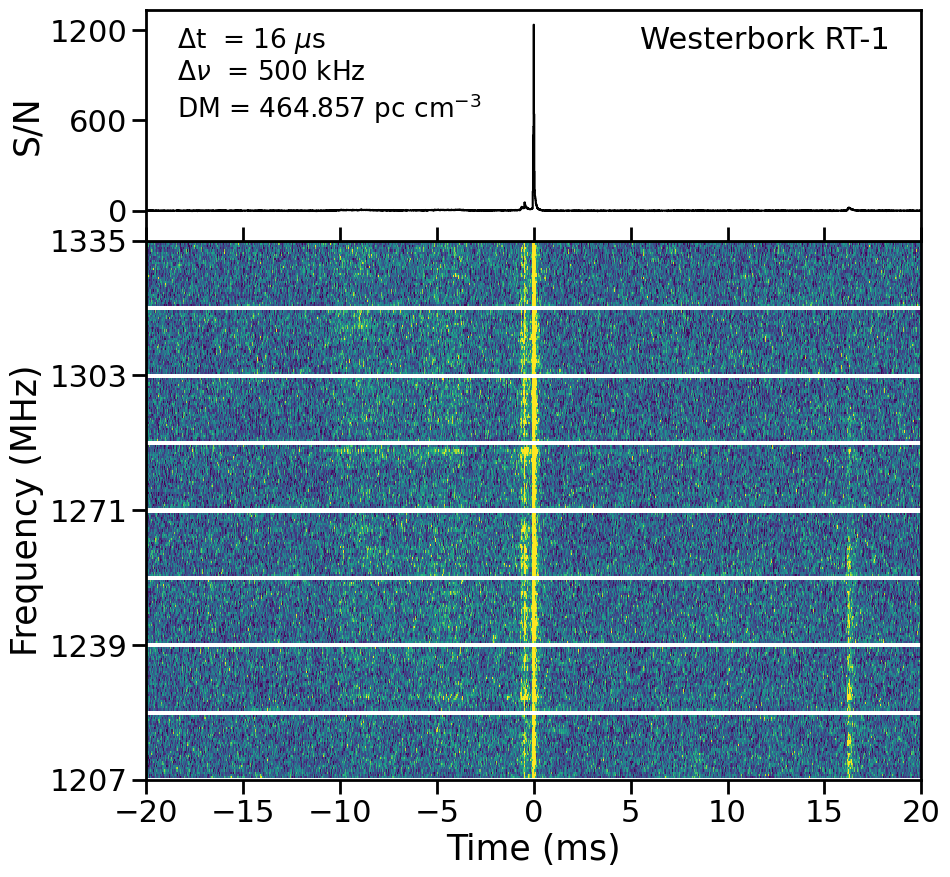

In [4]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=0.3398, window=20.0, downsamp_t=256, downsamp_f=1,\
                  id="Westerbork RT-1", dededisp=-464.857, plot_spectrum=False, wind_spectrum=None, save_bool=False)

the extent of the data is: [-680.0, 1111.9999999999995, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.266 pc/cc
de-dispersing to 465.266 pc/cc
Correcting for the bandpass
downsample factors are: time:128 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


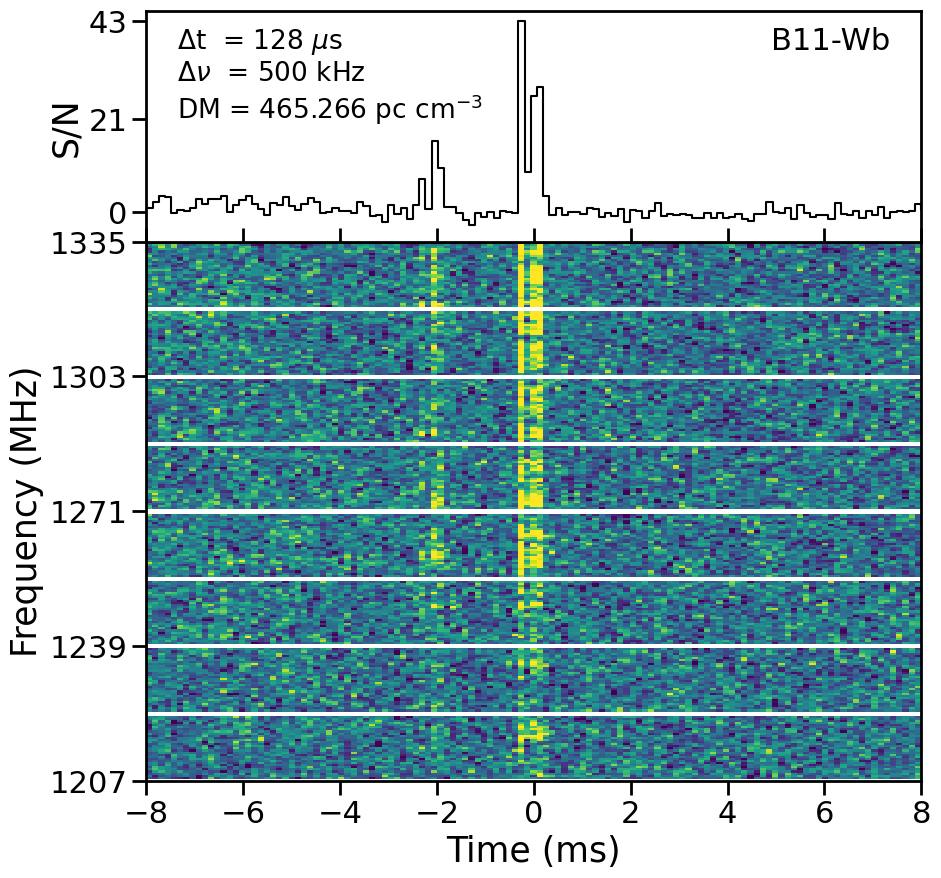

In [16]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55081_19/p55081_19_1us_500KHz_StokesI_DM465266.cor_Wb.fil", \
                  DM=465.266, offset_sec=0.68, window=8.0, downsamp_t=128, downsamp_f=1,\
                  id="B11-Wb", dededisp=-465.266, plot_spectrum=False, wind_spectrum=8, save_bool=False)

the extent of the data is: [-306.0, 1742.0, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.095 pc/cc
de-dispersing to 465.095 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
channel numbers: 4194304
bandwidth is: 128.0 . Number of channels: 4194304 . First subband array:  [     0      1 524286 524287]
Subband edges:  524288


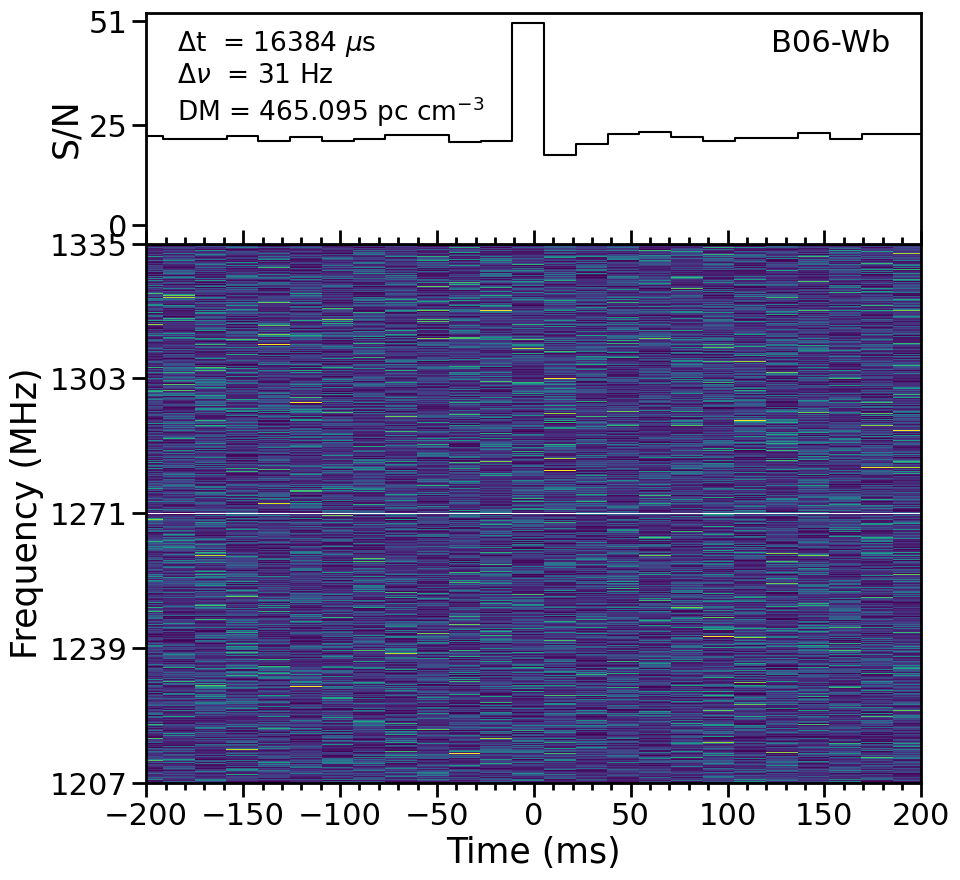

In [115]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55049_25/B06_p55049_25_16ms_30Hz_StokesI_DM465095_scin_Wb.fil", \
                  DM=465.095, offset_sec=0.306, window=200.0, downsamp_t=1, downsamp_f=1,\
                  id="B06-Wb", dededisp=-465.095, plot_spectrum=False, wind_spectrum=8, save_bool=False)

the extent of the data is: [-306.0, 1485.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.095 pc/cc
de-dispersing to 465.095 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
channel numbers: 65536
bandwidth is: 128.0 . Number of channels: 65536 . First subband array:  [   0    1 8190 8191]
Subband edges:  8192


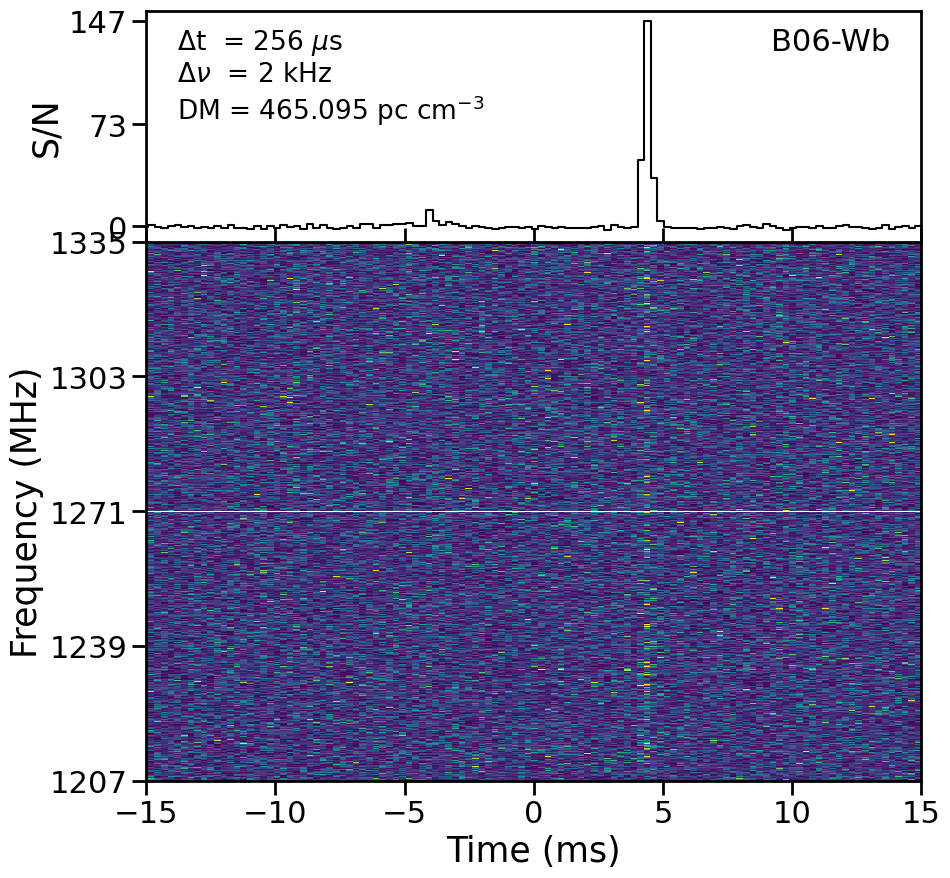

In [55]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55049_25/B06_p55049_25_256us_2KHz_StokesI_DM465095_scin.cor_Wb.fil", \
                  DM=465.095, offset_sec=0.306, window=15.0, downsamp_t=1, downsamp_f=1,\
                  id="B06-Wb", dededisp=-465.095, plot_spectrum=False, wind_spectrum=8, save_bool=False)

the extent of the data is: [-339.8, 1452.2, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:128 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


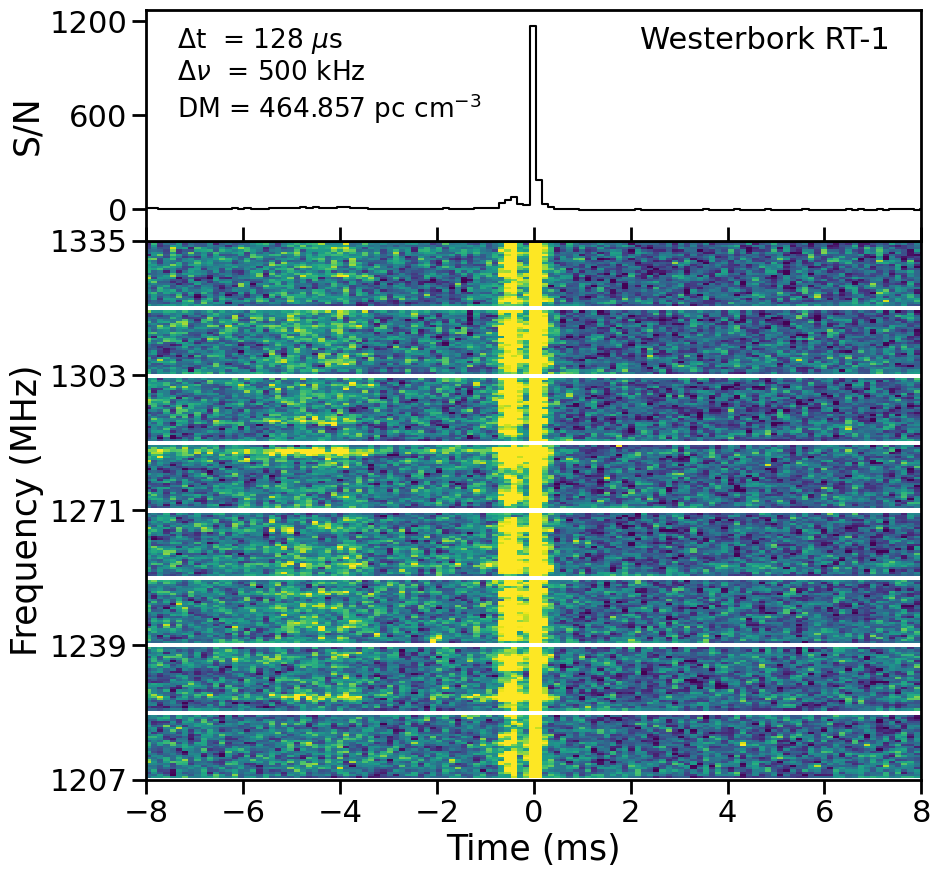

In [28]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=0.3398, window=8.0, downsamp_t=128, downsamp_f=1,\
                  id="Westerbork RT-1", dededisp=-464.857, plot_spectrum=False, wind_spectrum=None, save_bool=False)

In [ ]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=0.3398, window=8.0, downsamp_t=1, downsamp_f=1,\
                  id="B01-Wb", dededisp=-464.857, plot_spectrum=False, wind_spectrum=None, save_bool=False)

the extent of the data is: [-723.0, 1069.0, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:64 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


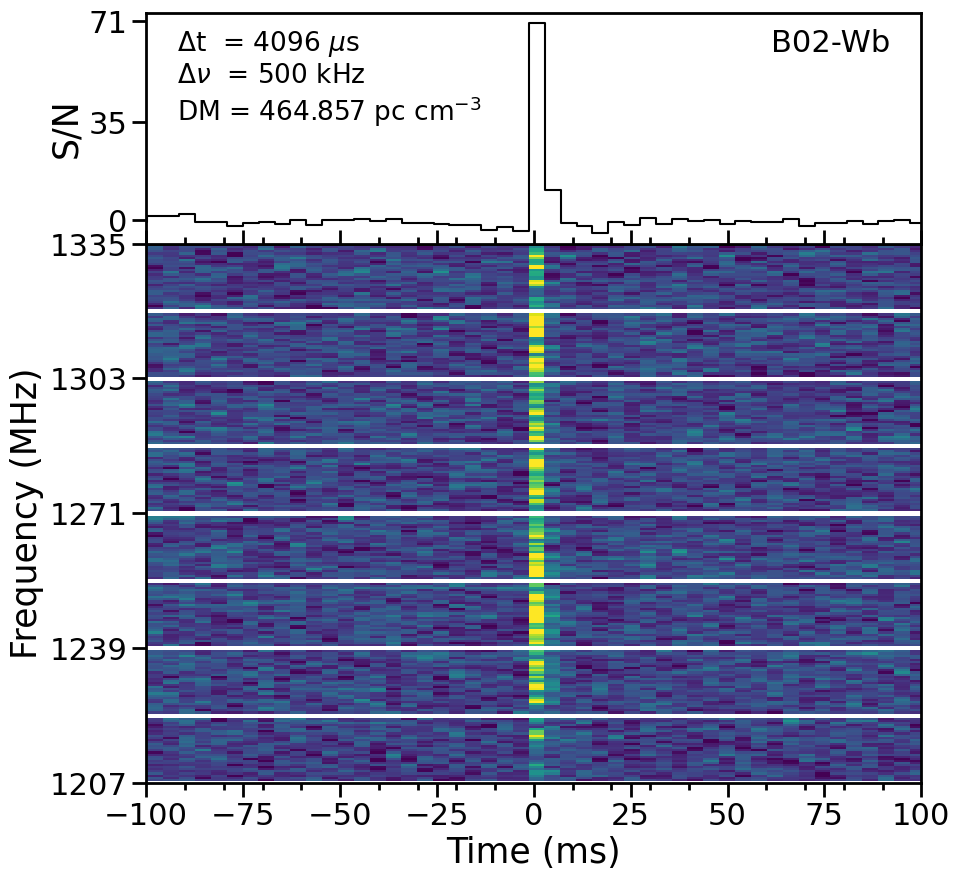

In [7]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55038_23/p55038_23_64us_500KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=0.723, window=100.0, downsamp_t=64, downsamp_f=1,\
                  id="B02-Wb", dededisp=-464.857, plot_spectrum=False, wind_spectrum=None, save_bool=False)

the extent of the data is: [-723.0, 813.0, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
channel numbers: 524288
bandwidth is: 128.0 . Number of channels: 524288 . First subband array:  [    0     1 65534 65535]
Subband edges:  65536


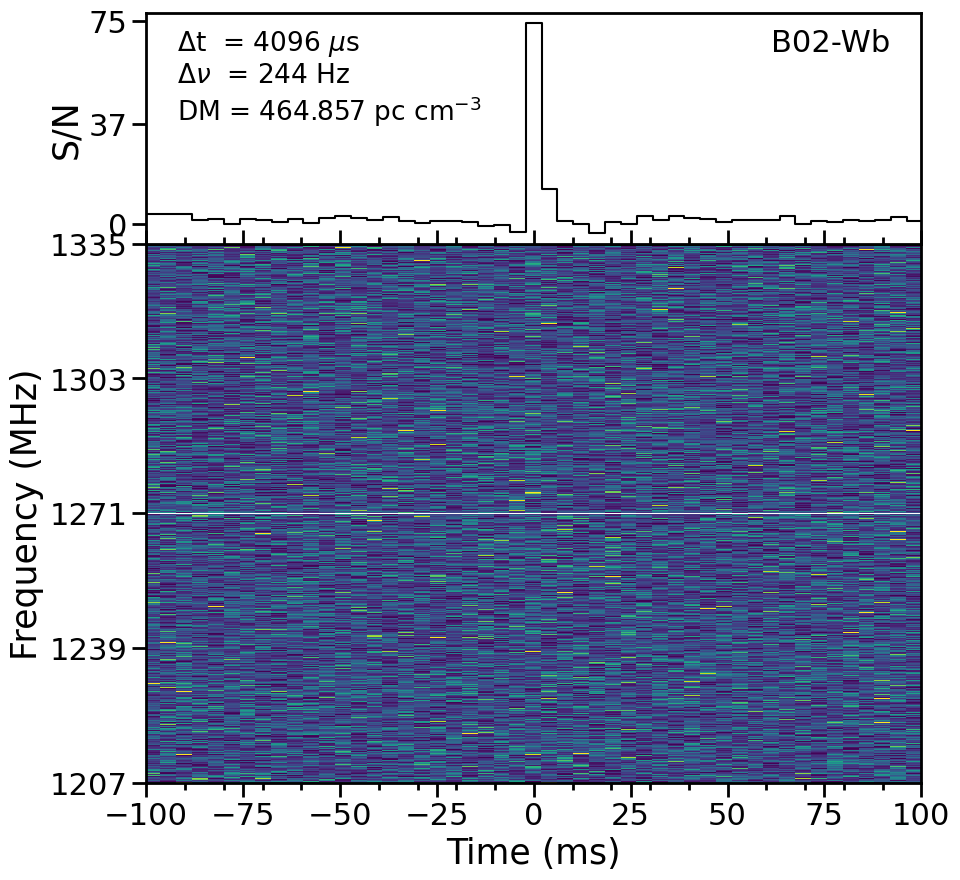

In [42]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55038_23/B02_p55038_23_4ms_244Hz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=0.723, window=100.0, downsamp_t=1, downsamp_f=1,\
                  id="B02-Wb", dededisp=-464.857, save_bool=False)

the extent of the data is: [-1235.0, 1580.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:512 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


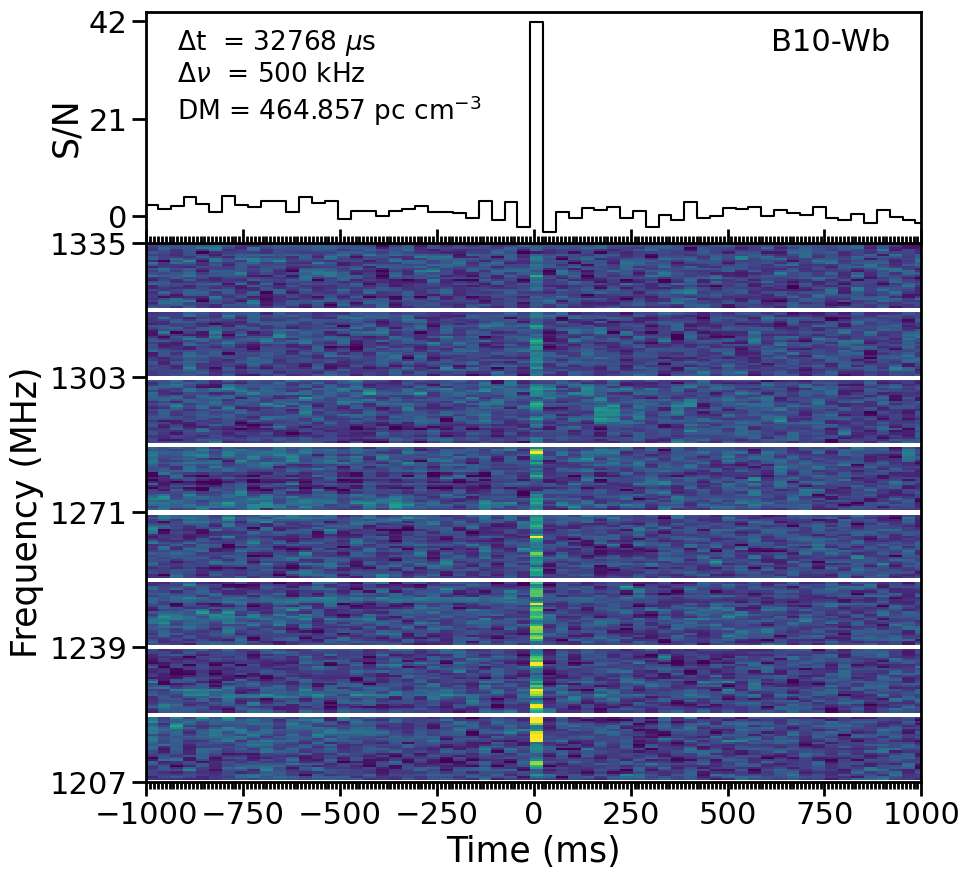

In [32]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55074_30/p55074_30_64us_500KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=1.235, window=1000, downsamp_t=512, downsamp_f=1,\
                  id="B10-Wb", dededisp=-464.857, save_bool=False)

the extent of the data is: [-1235.0, 1325.0, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
channel numbers: 1048576
bandwidth is: 128.0 . Number of channels: 1048576 . First subband array:  [     0      1 131070 131071]
Subband edges:  131072


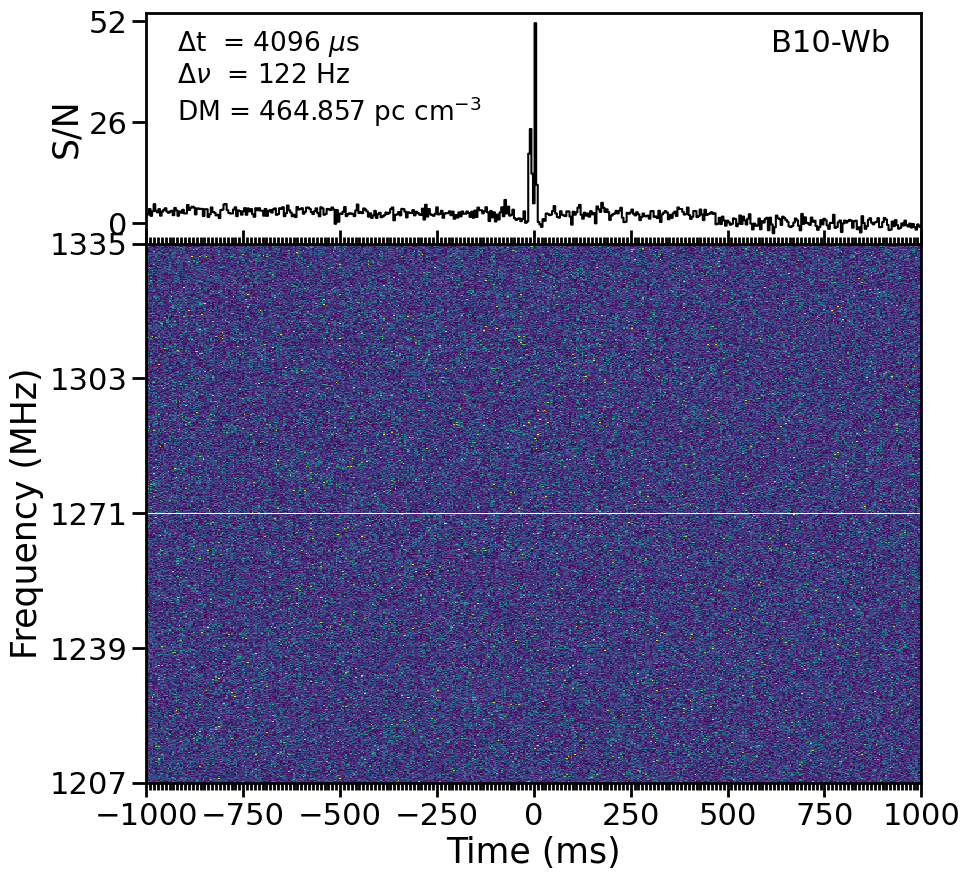

In [44]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55074_30/B10_p55074_30_4ms_122Hz_StokesI_DM464857.cor_Wb.fil", \
                  DM=464.857, offset_sec=1.235, window=1000, downsamp_t=1, downsamp_f=1,\
                  id="B10-Wb", dededisp=-464.857, save_bool=False)

the extent of the data is: [-1000.0, 1000.1587199999999, 1332.24609375, 1430.68359375]
loading in the data
de-dispersing to 464.857 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
channel numbers: 168
bandwidth is: 98.4375 . Number of channels: 168 . First subband array:  [ 0 20]
Subband edges:  21


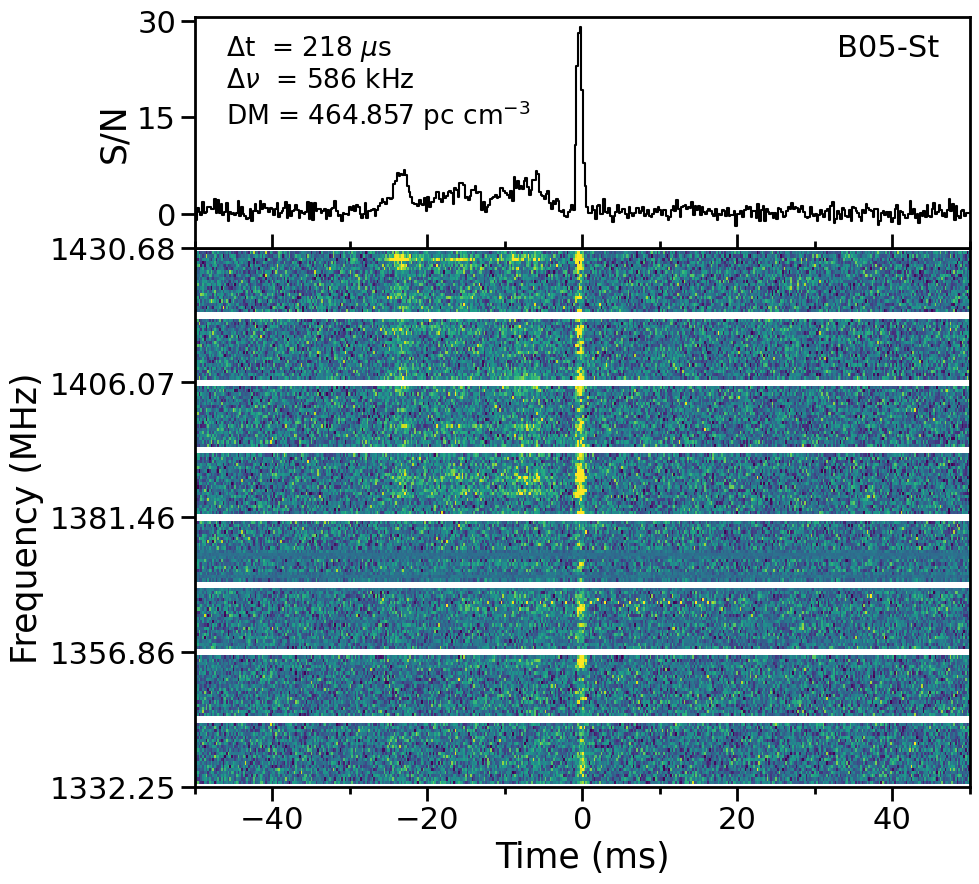

In [52]:
waterfaller_maker(burst="/scratch1/baseband_extractions/frb240619D_meerkat/stockert/snip60535.9395728.fbspi.fil", \
                  DM=464.857, offset_sec=1.0, window=50.0, downsamp_t=1, downsamp_f=1,\
                  id="B05-St", dededisp=None, plot_spectrum=False, wind_spectrum=30, save_bool=False)

the extent of the data is: [-723.0, 1069.0, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.857 pc/cc
de-dispersing to 465.2 pc/cc
Correcting for the bandpass
downsample factors are: time:4 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 1024
bandwidth is: 128.0 . Number of channels: 1024 . First subband array:  [  0   1 126 127]
Subband edges:  128


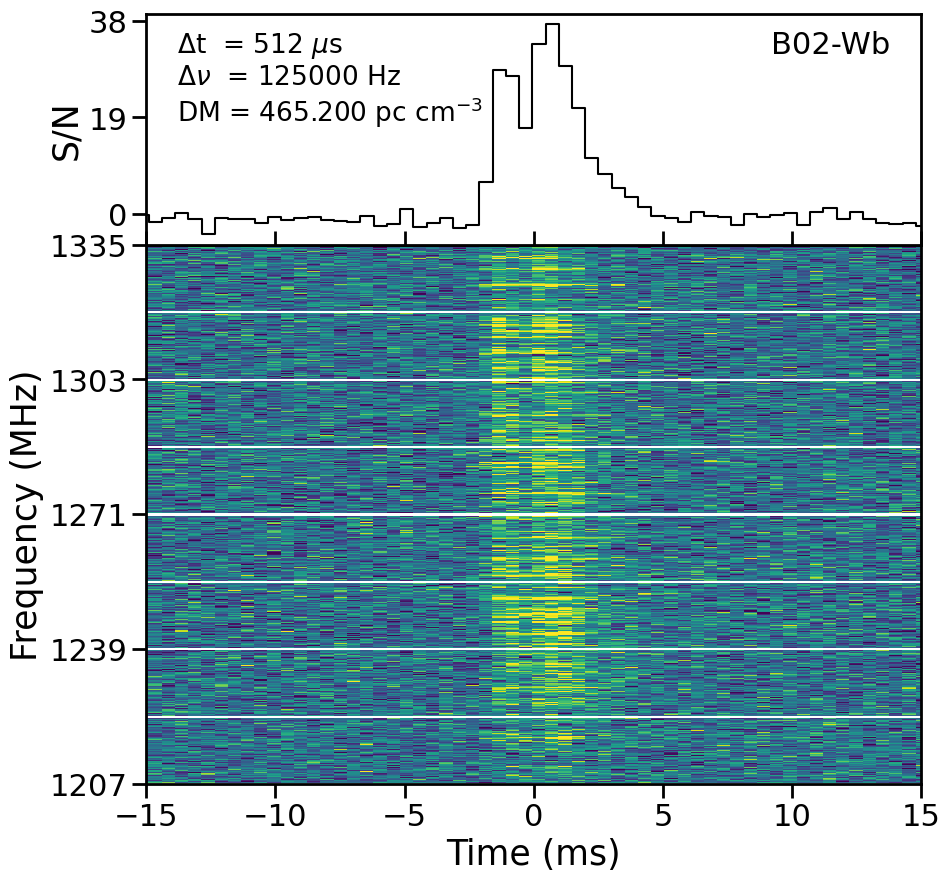

In [98]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55038_23/p55038_23_128us_125KHz_StokesI_DM464857.cor_Wb.fil", \
                  DM=465.2, offset_sec=0.723, window=15, downsamp_t=4, downsamp_f=1,\
                  id="B02-Wb", dededisp=-464.857, plot_spectrum=False, wind_spectrum=8, save_bool=False)

the extent of the data is: [-1010.0, 1805.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.86 pc/cc
de-dispersing to 464.86 pc/cc
Correcting for the bandpass
downsample factors are: time:4 and freq:4
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 1024
channel numbers: 256.0
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
plot_name: B05-Wb-p55048_24_64us_125KHz_StokesI_DM46486.cor_Wb_120ms_256us_500kHz


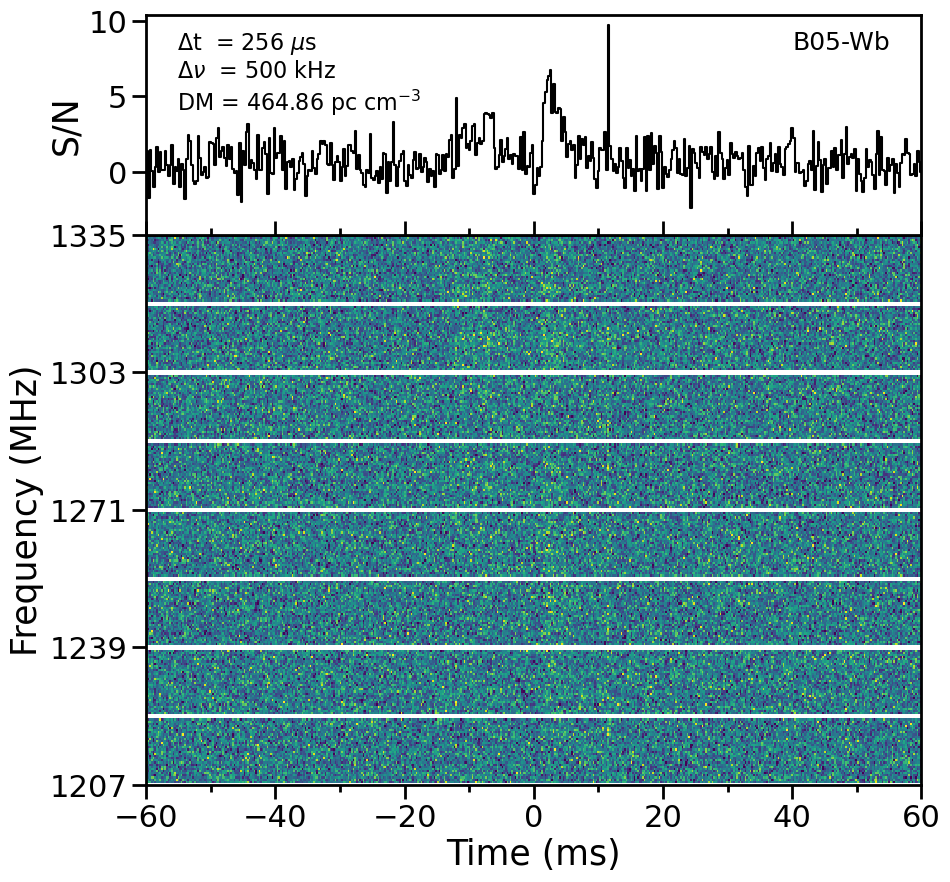

In [156]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55048_24/p55048_24_64us_125KHz_StokesI_DM46486.cor_Wb.fil", \
                  DM=464.86, offset_sec=1.01, window=60, downsamp_t=4, downsamp_f=4,\
                  id="B05-Wb", dededisp=-464.86)

the extent of the data is: [-1021.5000000000001, 1794.4999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.109 pc/cc
de-dispersing to 465.209 pc/cc
Correcting for the bandpass
downsample factors are: time:8 and freq:2
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 1024
bandwidth is: 128.0 . Number of channels: 512 . First subband array:  [ 0 63]
Subband edges:  64


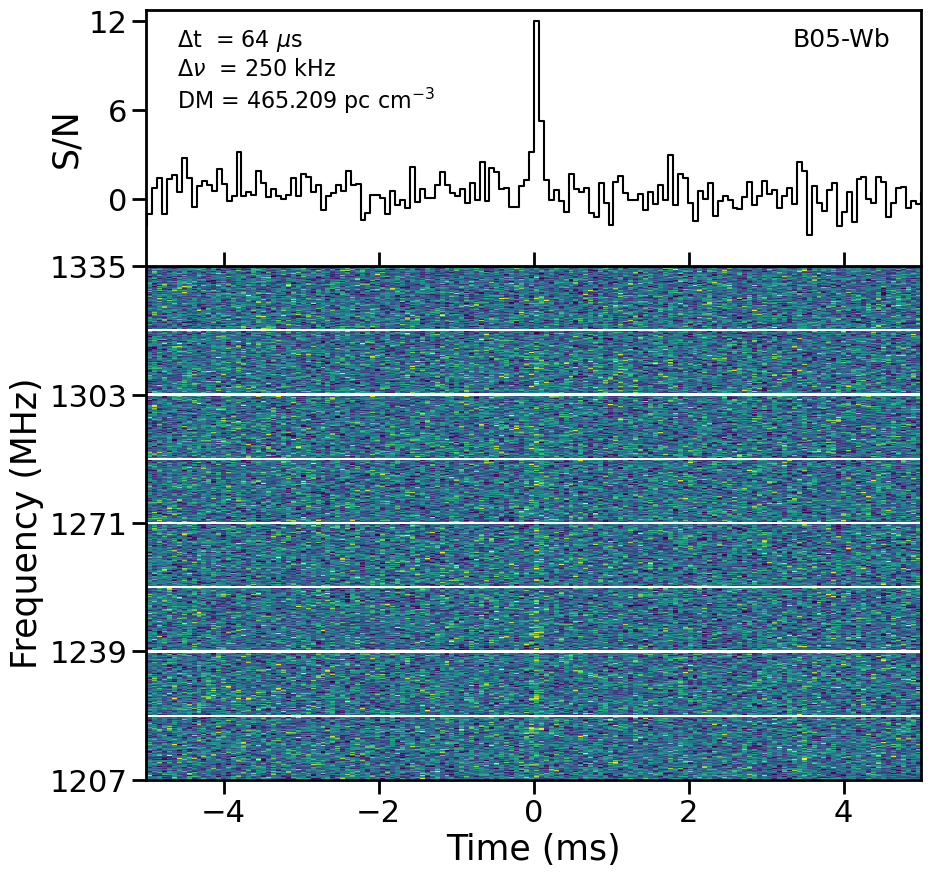

In [31]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55048_24/p55048_24_8us_125KHz_StokesI_DM465109.cor_Wb.fil", \
                  DM=465.209, offset_sec=1.0215, window=5, downsamp_t=8, downsamp_f=2,\
                  id="B05-Wb", dededisp=-465.109)

In [5]:
# waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55049_25/p55049_25_1us_500KHz_StokesI_DM46486.cor_Wb.fil", \
#                   DM=464.86, offset_sec=0.3105, window=5, downsamp_t=8, downsamp_f=1,\
#                   id="B06-Wb", dededisp=-464.86)

the extent of the data is: [-310.40000000000003, 1481.6, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.095 pc/cc
de-dispersing to 465.095 pc/cc
Correcting for the bandpass
downsample factors are: time:8 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
plot_name: B06-Wb-p55049_25_1us_500KHz_StokesI_DM465095.cor_Wb_4ms_8us_500kHz


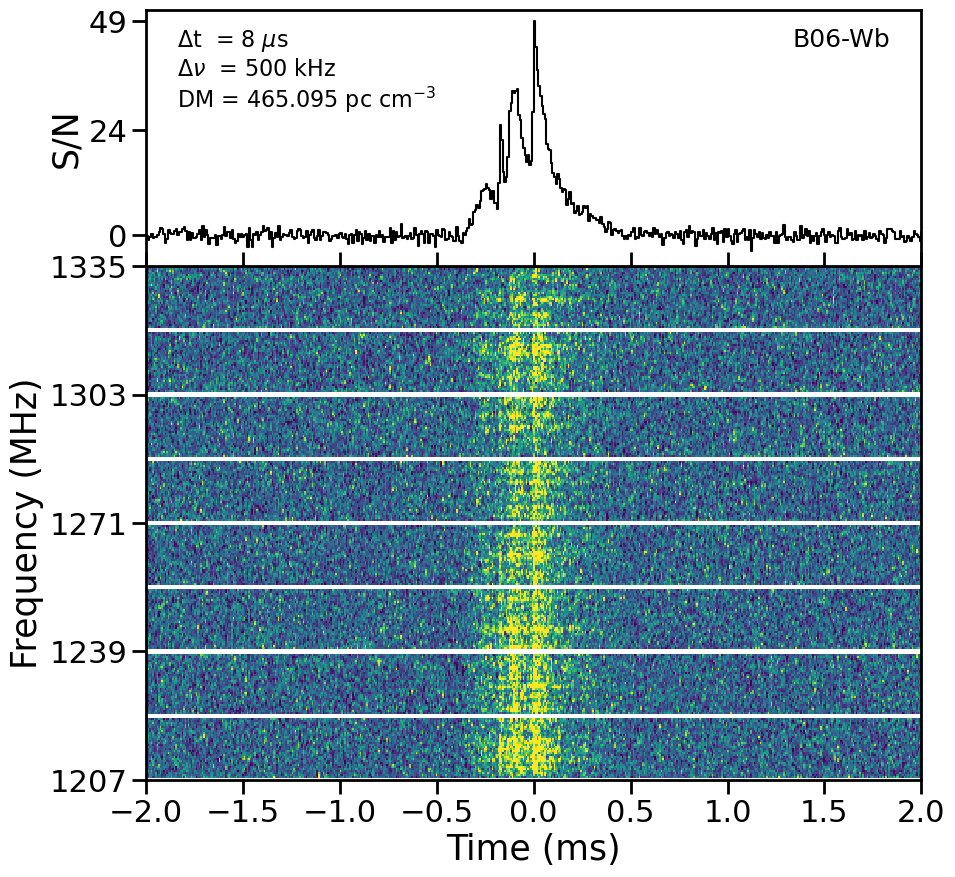

In [9]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55049_25/p55049_25_1us_500KHz_StokesI_DM465095.cor_Wb.fil", \
                  DM=465.095, offset_sec=0.3104, window=2, downsamp_t=8, downsamp_f=1,\
                  id="B06-Wb", dededisp=-465.095, save_bool=True)

the extent of the data is: [-756.0, 1035.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.3 pc/cc
de-dispersing to 465.3 pc/cc
Correcting for the bandpass
downsample factors are: time:64 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


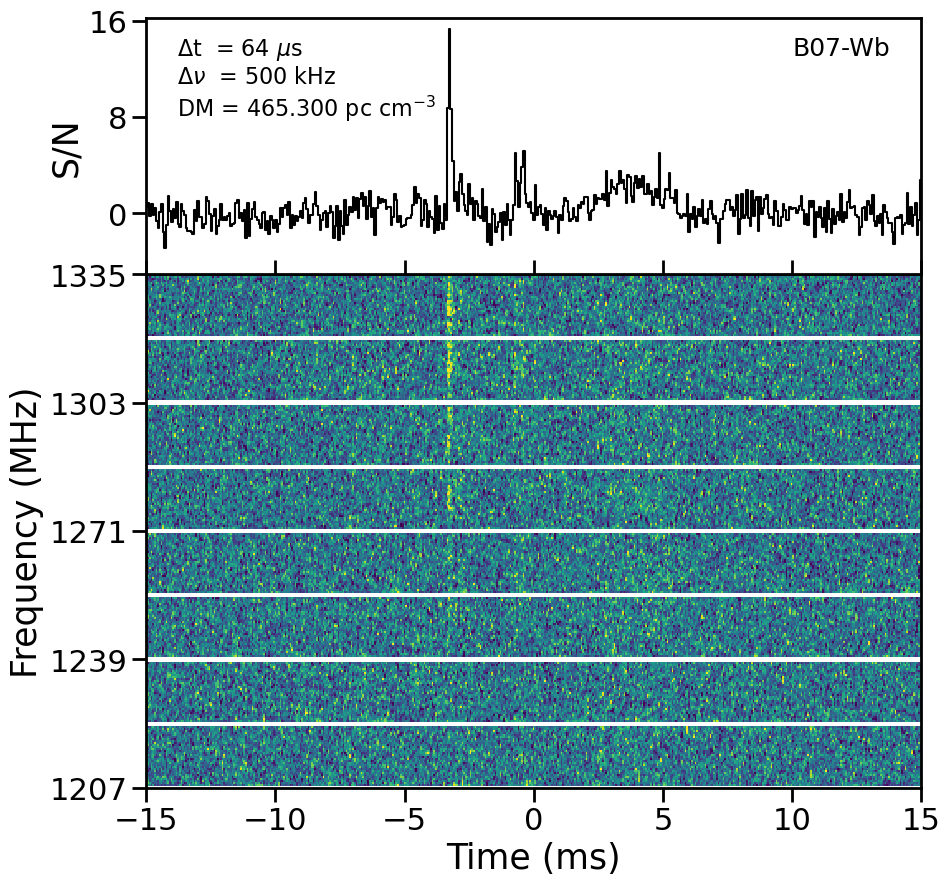

In [6]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55065_29/p55065_29_1us_500KHz_StokesI_DM465300.cor_Wb.fil", \
                  DM=465.3, offset_sec=0.756, window=15, downsamp_t=64, downsamp_f=1,\
                  id="B07-Wb", dededisp=-465.3)

the extent of the data is: [-756.0, 1035.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -465.294 pc/cc
de-dispersing to 465.294 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:4
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 1024
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


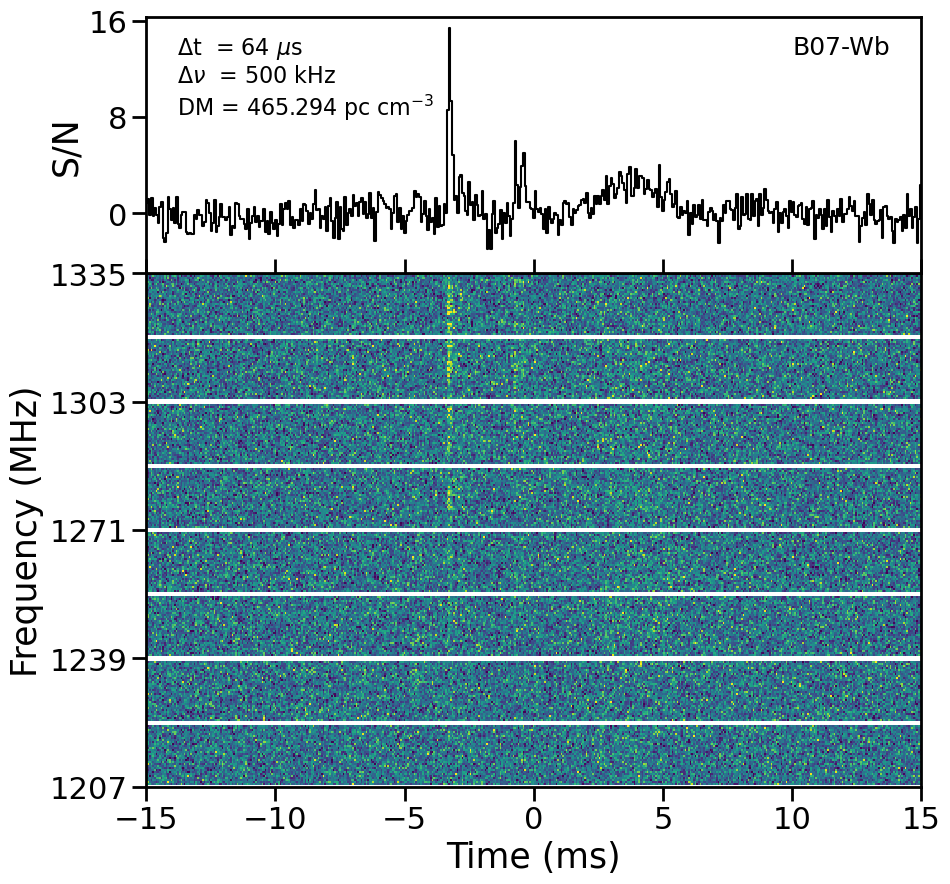

In [8]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55065_29/p55065_29_64us_125KHz_StokesI_DM465294.cor_Wb.fil", \
                  DM=465.294, offset_sec=0.756, window=15, downsamp_t=1, downsamp_f=4,\
                  id="B07-Wb", dededisp=-465.294)

the extent of the data is: [-1235.0, 1580.9999999999998, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.86 pc/cc
de-dispersing to 464.86 pc/cc
Correcting for the bandpass
downsample factors are: time:8 and freq:1
running downsampling and correcting bandpass
Masking subband edges
channel numbers: 256
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32


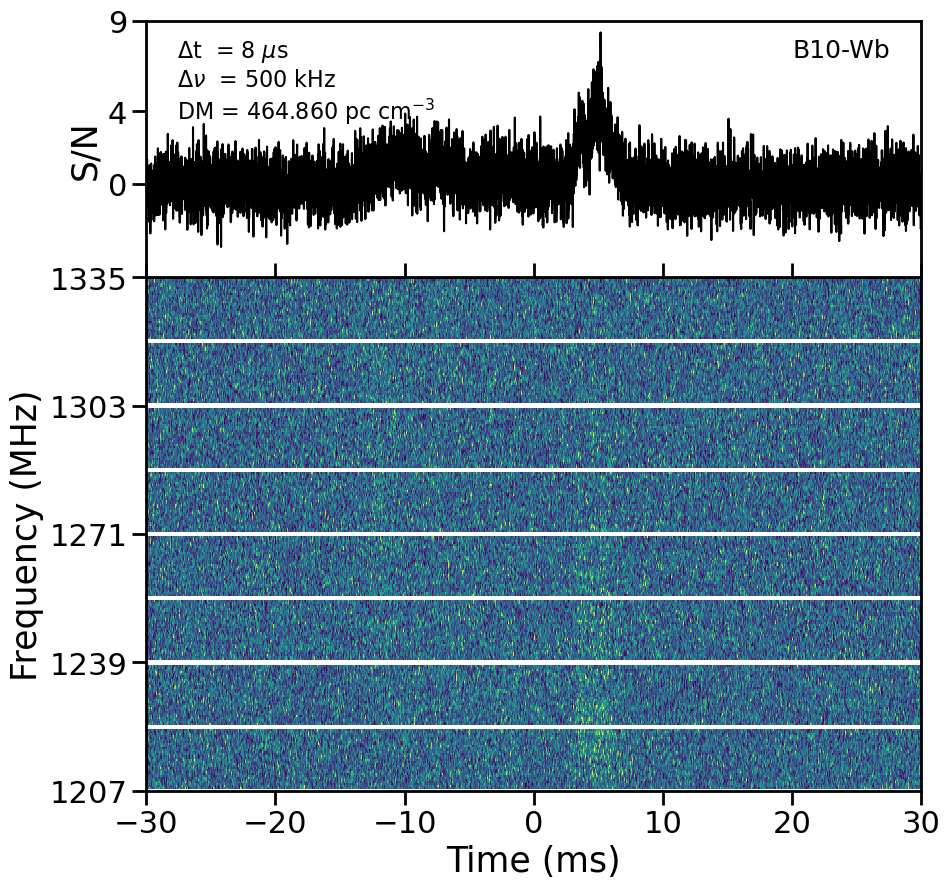

In [19]:
waterfaller_maker(burst="/data1/omar/sfxc/frb240619d/p55074_30/p55074_30_1us_500KHz_StokesI_DM46486.cor_Wb.fil", \
                  DM=464.86, offset_sec=1.235, window=30, downsamp_t=8, downsamp_f=1,\
                  id="B10-Wb", dededisp=-464.86)

In [41]:
def de_dedisp_sn_maximizer(dededisp):
    """
    The input burst is already dedisped by SFXC
    Will de-disperse the burst by giving a negative DM
    """

    burst = your.Your('/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb.fil')
    header_dict = frb_functions.your_header_to_dict(burst)

    tsamp = header_dict['tsamp']
    nbins = header_dict['nspectra']
    freqs = header_dict["freqs"]
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst,nstart=0, nsamp=nbins, npoln=1)
    I_ts = np.mean(d, axis=0)
    I_ts_peak_idx = np.argmax(I_ts)
    dm = dededisp
    range = 0.25
    dm_list = np.arange(dm-range,dm+range,0.0002)

    time_of_sweep_ms, bin_sweep = frb_functions.calc_sweep(chans=burst.chan_freqs,
                                                           tsamp=tsamp,
                                                           dm = dededisp + range)

    d = d[:, int(I_ts_peak_idx - bin_sweep) : int(I_ts_peak_idx + bin_sweep)] 
    I_ts = np.mean(d, axis=0)
    I_ts_peak_idx = np.argmax(I_ts)
    
    print("de-de-dispersing")
    stokes_i_dd = frb_functions.correct_bandpass(d)
    stokes_i_dd = frb_functions.dedisperse(stokes_i_dd,dededisp*-1,freqs,tsamp) 
    print("dedispersing loop started")
    max_sn = []
    
    for dm_dedisp in tqdm(dm_list):
        
        stokes_i = frb_functions.dedisperse(stokes_i_dd,dm_dedisp,freqs,tsamp)
        
        #make profile
        prof = np.mean(stokes_i,axis=0)
        stokes_i_normprof = frb_functions.normalize_1d(prof)
    
        stokes_i_normprof = stokes_i_normprof[I_ts_peak_idx - 1000 : I_ts_peak_idx + 1000] #hardcoded
        sn_peak = np.max(stokes_i_normprof)
        max_sn.append(sn_peak)

    df = pd.DataFrame(data = {"DM":dm_list,\
                              "SN":max_sn})

    name = header_dict["basename"] + f"_{len(dm_list)}_dmtrials"
    print(name)
    df.to_csv(f"{name}_46486.csv",header=True, index=True)

    return df

In [42]:
#This was already run a while ago :) 
df_dm_trials = de_dedisp_sn_maximizer(dededisp=464.86)

loading in the data
The duration of the sweep is: 0.241 seconds
The duration of the sweep is: 240.896 milliseconds
The duration of the sweep is: 240896.272 mircoseconds
This corresponds to 240897 time-bins.
de-de-dispersing
dedispersing loop started


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [39:57<00:00,  1.04it/s]


p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb_2500_dmtrials


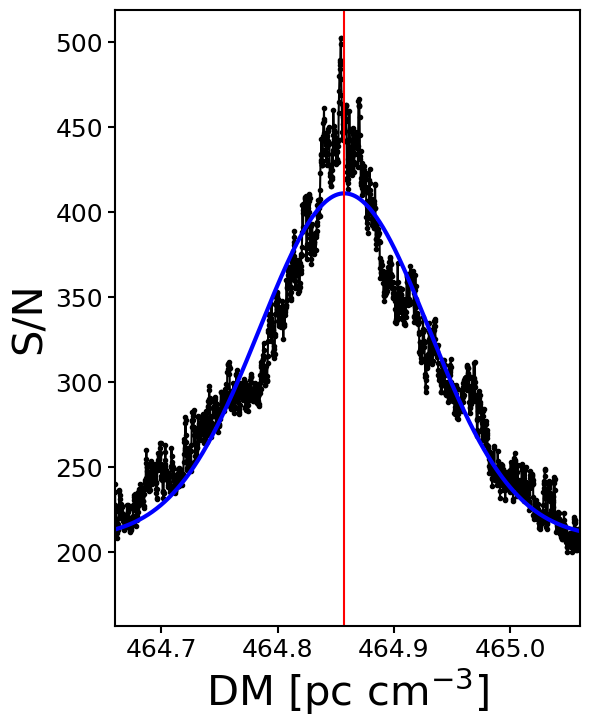

max 464.8544000000081
[2.02893207e+02 4.64857257e+02 7.29856771e-02 2.08081193e+02]
gerr [1.03845173e+00 3.66973163e-04 5.28961739e-04 7.60711339e-01]
464.857 0.004


In [53]:
def sn_vs_dm_1peak(csv):

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)

    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    #df_filter = df[(df['DM'] > 219.65) & (df['DM'] < 219.8)] 
    sn_filter = df["SN"].values
    dm_filter = df["DM"].values

    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[200,464.87,0.1,200], maxfev=10000)
    
    #Retrieving the entire grid space from the df
    sn_range = df["SN"].values 
    dm_range = df["DM"].values 
    
    ##Figure
    fig,ax=plt.subplots(figsize=(6,8))
    
    #Plotting the whole range
    plt.plot(dm_range, sn_range,'.',color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    plt.plot(dm_space,gaus(dm_space,*poptc),color='b',lw=3,label='B128-Wb')
    
    plt.axvline(poptc[1],color='red')
    #plt.axvline(poptc[1]+poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    #plt.axvline(poptc[1]-poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    
    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5)
        
    plt.xlabel(r'DM [pc cm$^{-3}]$',size=30)
    plt.ylabel('S/N',size=30)
    #plt.ylim(18.2,21)
    dm = 464.86
    offset = 0.2
    plt.xlim(dm-offset,dm+offset)
    
    # plt.legend(fontsize=14)
    # plt.savefig('snvdm_wb_p.pdf',dpi=300)
    plt.show()
    
    print(f'max {dm_range[np.argmax(sn_range)]}')
    print(f"{poptc}")
    print(f'gerr {np.sqrt(np.diag(pcovc))}')
    print(f'{np.round(poptc[1],3)} {np.round(3*poptc[2]/np.sqrt(len(dm_range)),3)}')
    
    return

sn_vs_dm_1peak(csv="p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb_2500_dmtrials_46486.csv")

In [66]:
frb_functions.calc_sweep(chans=[1200,1300],dm=465,tsamp=0.1)

The duration of the sweep is: 0.198 seconds
The duration of the sweep is: 198.211 milliseconds
The duration of the sweep is: 198210.530 mircoseconds
This corresponds to 2 time-bins.


(198.21052976175875, 2)